Import libraries

In [12]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, fcluster

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


Compare Linear Regression, Ridge Regression and Lasso Regression using regression evaluation metrics.

Regression Model Performance:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,42.7941,2900.1936,53.8534,0.4526
1,Ridge Regression,42.8120,2892.0146,53.7775,0.4541
2,Lasso Regression,42.8030,2824.5681,53.1467,0.4669


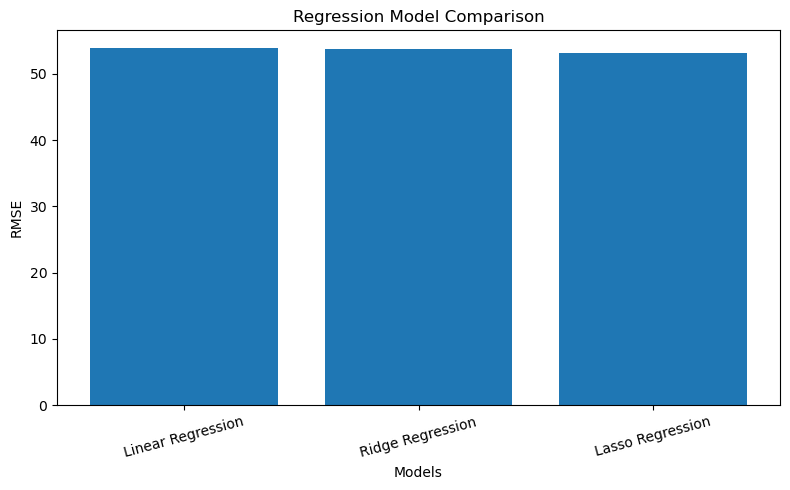

In [13]:
# Load Diabetes regression dataset
data = load_diabetes()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=1.0, max_iter=10000)
}

results = []

# Train and evaluate models
for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mse = mean_squared_error(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print("Regression Model Performance:")
display(results_df.round(4))

# Comparison graph
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.xlabel("Models")
plt.ylabel("RMSE")
plt.title("Regression Model Comparison")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Evaluate Decision Tree and Logistic Regression models using the Breast Cancer dataset.

Classification Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree (Gini),0.9123,0.9559,0.9028,0.9286,0.9157
1,Logistic Regression (L2),0.9825,0.9861,0.9861,0.9861,0.9954
2,Logistic Regression (L1),0.9912,0.9863,1.0000,0.9931,0.9967



Model: Decision Tree (Gini)
Confusion Matrix:
[[39  3]
 [ 7 65]]
Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


Model: Logistic Regression (L2)
Confusion Matrix:
[[41  1]
 [ 1 71]]
Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Model: Logistic Regression (L1)
Confusion Matrix:
[[41  1]
 [ 0 72]]
Classification Report:
              precision    recall  f1-score   support

   malignant    

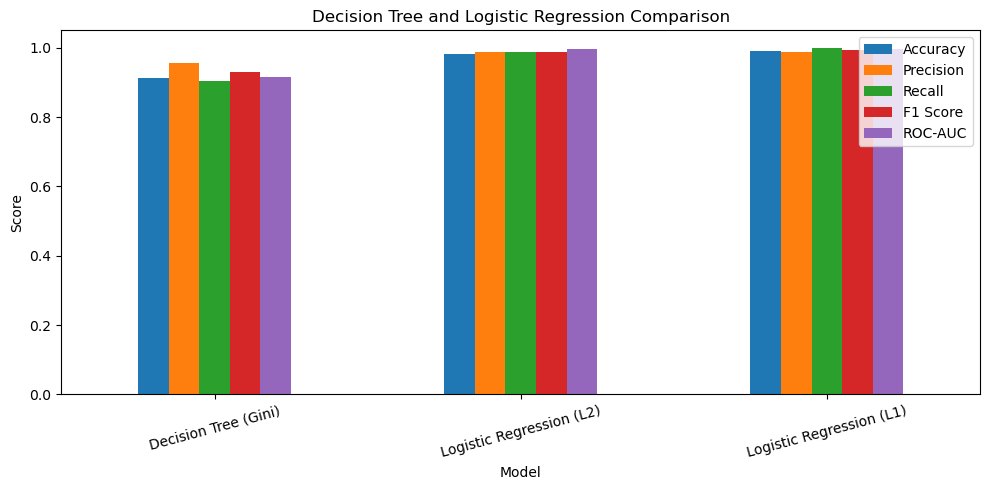

In [14]:
# Load Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create models
models = {
    "Decision Tree (Gini)": DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),

    "Logistic Regression (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=1.0,
            max_iter=5000
        )
    ),

    "Logistic Regression (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=1.0,
            max_iter=5000
        )
    )
}

results = []
predictions_dict = {}

# Train and evaluate
for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    predictions_dict[name] = predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("Classification Model Performance:")
display(results_df.round(4))

# Confusion matrix and classification report
for name, predictions in predictions_dict.items():

    print("\nModel:", name)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("Classification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=data.target_names
    ))

# Comparison graph
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Decision Tree and Logistic Regression Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Evaluate K-Nearest Neighbors using the Social Network Ads dataset

KNN Model Performance
Accuracy: 0.9
Precision: 0.8387096774193549
Recall: 0.896551724137931
F1 Score: 0.8666666666666667
ROC-AUC: 0.9303583502366464

Confusion Matrix:
[[46  5]
 [ 3 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92        51
           1       0.84      0.90      0.87        29

    accuracy                           0.90        80
   macro avg       0.89      0.90      0.89        80
weighted avg       0.90      0.90      0.90        80



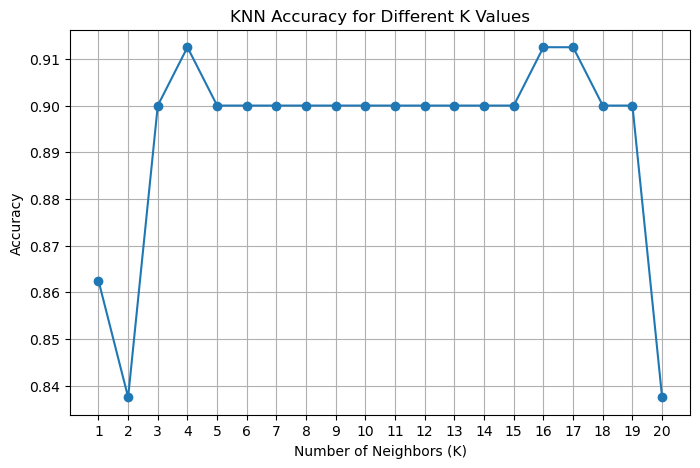

In [15]:
# Load dataset
data = pd.read_csv(r"C:\Users\omgow\OneDrive\Desktop\MSIS\AML_LAB\Datasets\Social_Network_Ads.csv")

# Select input and target columns
X = data[["Gender", "Age", "EstimatedSalary"]].copy()
y = data["Purchased"]

# Convert Gender into numerical values
X["Gender"] = X["Gender"].map({
    "Female": 0,
    "Male": 1
})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create KNN model with scaling
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train model
knn_model.fit(X_train, y_train)

# Prediction
predictions = knn_model.predict(X_test)
probabilities = knn_model.predict_proba(X_test)[:, 1]

# Evaluation
print("KNN Model Performance")

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1 Score:", f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

# Compare different K values
k_values = range(1, 21)
accuracies = []

for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    accuracies.append(accuracy_score(y_test, pred))

# Plot K values
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")

plt.xticks(list(k_values))
plt.grid()
plt.show()

Evaluate Gaussian Naive Bayes using the Diabetes dataset

In [16]:
# Load dataset
data = pd.read_csv(r"C:\Users\omgow\OneDrive\Desktop\MSIS\AML_LAB\Datasets\diabetes.csv")

# Separate features and target
X = data.drop(columns=["Outcome"])
y = data["Outcome"].astype(int)

# Replace invalid zero values with missing values
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Naive Bayes pipeline
nb_model = make_pipeline(
    SimpleImputer(strategy="median"),
    GaussianNB()
)

# Train model
nb_model.fit(X_train, y_train)

# Prediction
predictions = nb_model.predict(X_test)
probabilities = nb_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Naive Bayes Model Performance")

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1 Score:", f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Naive Bayes Model Performance
Accuracy: 0.7012987012987013
Precision: 0.5666666666666667
Recall: 0.6296296296296297
F1 Score: 0.5964912280701754
ROC-AUC: 0.7646296296296297

Confusion Matrix:
[[74 26]
 [20 34]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.74      0.76       100
           1       0.57      0.63      0.60        54

    accuracy                           0.70       154
   macro avg       0.68      0.68      0.68       154
weighted avg       0.71      0.70      0.70       154



Compare Random Forest, AdaBoost and Gradient Boosting

Ensemble Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.9000,0.8387,0.8966,0.8667,0.9446
1,AdaBoost,0.8625,0.8000,0.8276,0.8136,0.9496
2,Gradient Boosting,0.9000,0.8387,0.8966,0.8667,0.9513


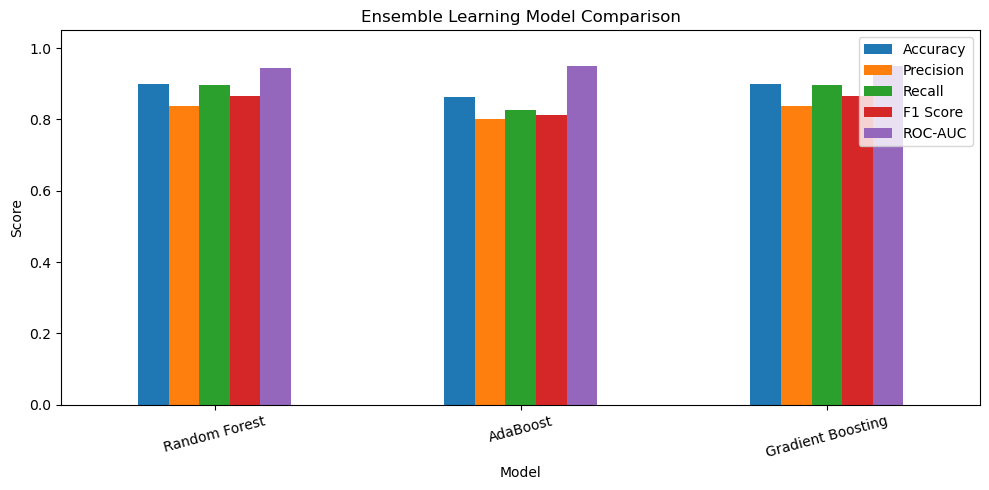

In [17]:
# Use Social Network Ads dataset
data = pd.read_csv(r"C:\Users\omgow\OneDrive\Desktop\MSIS\AML_LAB\Datasets\Social_Network_Ads.csv")

X = data[["Gender", "Age", "EstimatedSalary"]].copy()
y = data["Purchased"]

X["Gender"] = X["Gender"].map({
    "Female": 0,
    "Male": 1
})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create ensemble models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

results = []

# Train and evaluate
for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("Ensemble Model Performance:")
display(results_df.round(4))

# Comparison graph
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Ensemble Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Compare K-Means, Hierarchical Clustering and Gaussian Mixture Model.

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Clustering Model Performance:


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.4601,0.7184,1080.8724
1,Hierarchical,0.3804,0.7542,901.8178
2,Gaussian Mixture,0.4013,0.7953,794.5632


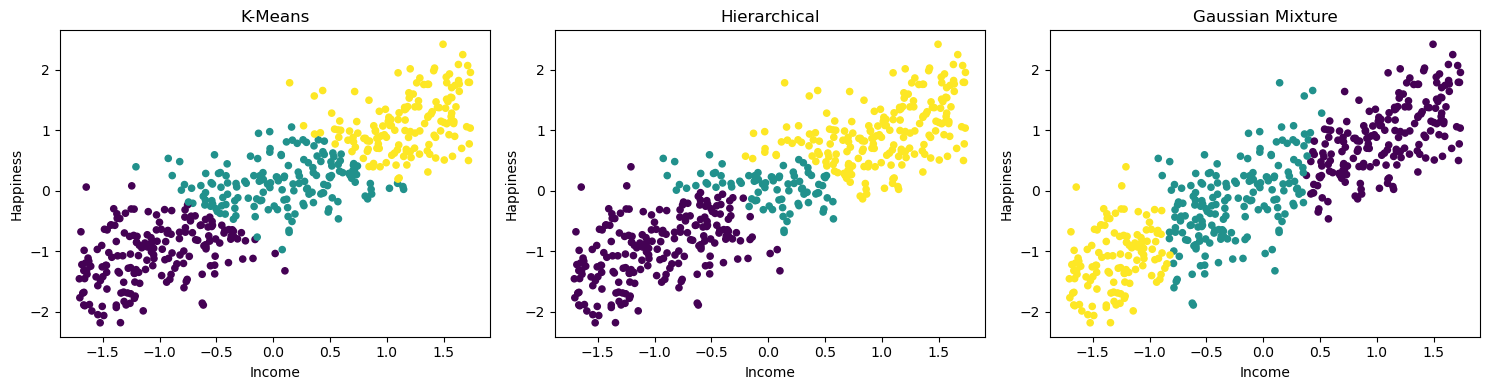

GMM Converged: True
GMM AIC: 2051.7887149845756
GMM BIC: 2123.3689162939945


In [18]:
# Load income dataset
data = pd.read_csv(r"C:\Users\omgow\OneDrive\Desktop\MSIS\AML_LAB\Datasets\income_data.csv")

# Select features
X = data[["income", "happiness"]].dropna()

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Hierarchical clustering
Z = linkage(X_scaled, method="ward")

hierarchical_labels = fcluster(
    Z,
    t=3,
    criterion="maxclust"
)

# Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42
)

gmm_labels = gmm.fit_predict(X_scaled)

# Store clustering results
models = {
    "K-Means": kmeans_labels,
    "Hierarchical": hierarchical_labels,
    "Gaussian Mixture": gmm_labels
}

results = []

# Evaluate clustering models
for name, labels in models.items():

    results.append({
        "Model": name,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, labels)
    })

results_df = pd.DataFrame(results)

print("Clustering Model Performance:")
display(results_df.round(4))

# Visualize clusters
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, labels) in zip(axes, models.items()):

    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=20
    )

    ax.set_title(name)
    ax.set_xlabel("Income")
    ax.set_ylabel("Happiness")

plt.tight_layout()
plt.show()

# GMM evaluation
print("GMM Converged:", gmm.converged_)
print("GMM AIC:", gmm.aic(X_scaled))
print("GMM BIC:", gmm.bic(X_scaled))

: Apply Principal Component Analysis to reduce the dimensionality of the Diabetes dataset and visualize the data.

Variance explained by PC1: 0.2617974931611009
Variance explained by PC2: 0.21640126757746517
Total variance retained: 0.47819876073856604


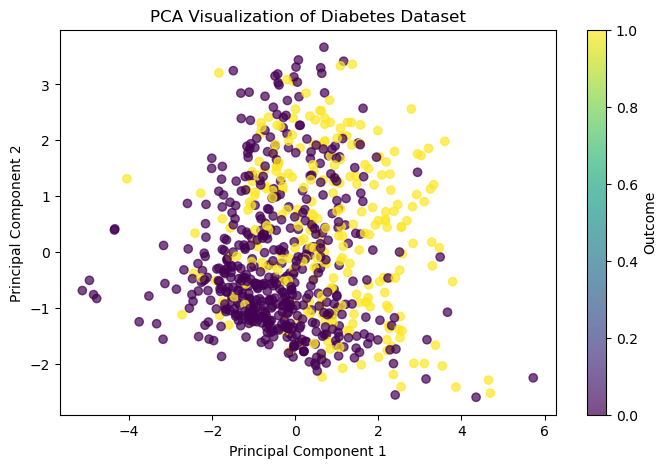

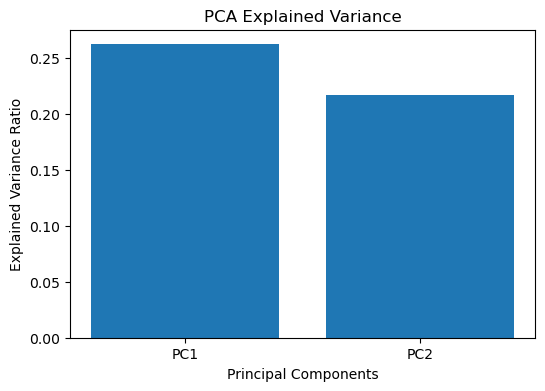

In [19]:
# Load Diabetes dataset
data = pd.read_csv(r"C:\Users\omgow\OneDrive\Desktop\MSIS\AML_LAB\Datasets\diabetes.csv")

# Separate features and target
X = data.drop(columns=["Outcome"])
y = data["Outcome"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained = pca.explained_variance_ratio_

print("Variance explained by PC1:", explained[0])
print("Variance explained by PC2:", explained[1])

print("Total variance retained:", explained.sum())

# PCA scatter plot
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Diabetes Dataset")

plt.colorbar(scatter, label="Outcome")
plt.show()

# Explained variance graph
plt.figure(figsize=(6, 4))

plt.bar(
    ["PC1", "PC2"],
    explained
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")

plt.show()

Overall model comparison and conclusion

In [23]:
print("=" * 60)
print("ASSIGNMENT 3: OVERALL PERFORMANCE ANALYSIS")
print("=" * 60)

print("\n1. REGRESSION MODELS")
print("Evaluated using MAE, MSE, RMSE and R2 Score.")
print("Lower MAE, MSE and RMSE indicate better performance.")
print("Higher R2 Score indicates better performance.")

print("\n2. CLASSIFICATION MODELS")
print("Decision Tree, Logistic Regression, KNN and Naive Bayes")
print("Evaluated using Accuracy, Precision, Recall, F1 Score and ROC-AUC.")
print("Higher values generally indicate better classification performance.")

print("\n3. ENSEMBLE MODELS")
print("Random Forest, AdaBoost and Gradient Boosting")
print("Compared using Accuracy, Precision, Recall, F1 Score and ROC-AUC.")

print("\n4. CLUSTERING MODELS")
print("K-Means, Hierarchical Clustering and Gaussian Mixture Model")

print("\nClustering Performance Results:")
display(results_df.round(4))

print("\n5. PRINCIPAL COMPONENT ANALYSIS")
print("Number of Principal Components:", pca.n_components_)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Retained:",
      round(sum(pca.explained_variance_ratio_), 4))

print("\n" + "=" * 60)
print("FINAL CONCLUSION")
print("=" * 60)

print("""
Different machine learning models were evaluated using suitable
performance metrics.

Regression models were compared using error-based metrics and R2.
Classification models were compared using classification metrics.
Ensemble methods were evaluated to understand their predictive
performance.
Clustering algorithms were compared using clustering evaluation
metrics.
PCA was used to reduce dimensionality and retain important information.

The results show that model performance depends on the dataset,
algorithm and evaluation metric. The most suitable model should be
selected based on the problem requirements.
""")

ASSIGNMENT 3: OVERALL PERFORMANCE ANALYSIS

1. REGRESSION MODELS
Evaluated using MAE, MSE, RMSE and R2 Score.
Lower MAE, MSE and RMSE indicate better performance.
Higher R2 Score indicates better performance.

2. CLASSIFICATION MODELS
Decision Tree, Logistic Regression, KNN and Naive Bayes
Evaluated using Accuracy, Precision, Recall, F1 Score and ROC-AUC.
Higher values generally indicate better classification performance.

3. ENSEMBLE MODELS
Random Forest, AdaBoost and Gradient Boosting
Compared using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

4. CLUSTERING MODELS
K-Means, Hierarchical Clustering and Gaussian Mixture Model

Clustering Performance Results:


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.4601,0.7184,1080.8724
1,Hierarchical,0.3804,0.7542,901.8178
2,Gaussian Mixture,0.4013,0.7953,794.5632



5. PRINCIPAL COMPONENT ANALYSIS
Number of Principal Components: 2
Explained Variance Ratio: [0.26179749 0.21640127]
Total Variance Retained: 0.4782

FINAL CONCLUSION

Different machine learning models were evaluated using suitable
performance metrics.

Regression models were compared using error-based metrics and R2.
Classification models were compared using classification metrics.
Ensemble methods were evaluated to understand their predictive
performance.
Clustering algorithms were compared using clustering evaluation
metrics.
PCA was used to reduce dimensionality and retain important information.

The results show that model performance depends on the dataset,
algorithm and evaluation metric. The most suitable model should be
selected based on the problem requirements.

